# Ingestion benchmarks

How well do we get text out of each corpus PDF, and what chunks does the project chunker produce from it?

1. Extraction: `pypdf` (current loader) vs `PyMuPDF` - speed and empty pages.
2. Text quality: characters per page, share of non-text characters.
3. Chunking: chunk count and size against the 400-600 token target in `docs/ingestion_details.md`.

In [1]:
import sys
from pathlib import Path

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "corpus").is_dir())  # repo root, wherever the notebook lives
CORPUS = REPO / "corpus"
sys.path.insert(0, str(REPO / "backend"))  # so `src.rag...` imports work

import hashlib


def unique_pdfs(folder):
    """PDFs in a folder, skipping byte-identical copies so nothing is embedded twice."""
    seen, pdfs = set(), []
    for path in sorted(folder.glob("*.pdf")):
        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        if digest not in seen:
            seen.add(digest)
            pdfs.append(path)
    return pdfs


PDFS = unique_pdfs(CORPUS)
[p.name for p in PDFS]

['20260914-NDRRMC-IRR-RA12287.pdf',
 'DISASTER PREPAREDNESS MANUAL.pdf',
 'ncrpasig-marikina-laguna-de-bay.pdf',
 'MMFMP.pdf']

## 1. Extraction speed and empty pages
A page with almost no text is probably a scan (needs OCR).

In [2]:
import time
import pandas as pd
import pymupdf
from pypdf import PdfReader

EMPTY_PAGE_CHARS = 50  # fewer characters than this counts as an empty page


def extract_pypdf(path):
    """Return one text string per page using pypdf."""
    return [page.extract_text() or "" for page in PdfReader(str(path)).pages]


def extract_pymupdf(path):
    """Return one text string per page using PyMuPDF."""
    with pymupdf.open(str(path)) as doc:
        return [page.get_text() for page in doc]


extractors = {"pypdf": extract_pypdf, "pymupdf": extract_pymupdf}
pages_by_run = {}  # (file, extractor) -> list of page texts
rows = []
for path in PDFS:
    for name, extract in extractors.items():
        start = time.perf_counter()
        pages = extract(path)
        seconds = time.perf_counter() - start
        pages_by_run[(path.name, name)] = pages
        lengths = [len(p.strip()) for p in pages]
        rows.append({
            "file": path.name, "extractor": name, "pages": len(pages),
            "seconds": round(seconds, 2),
            "empty_pages": sum(n < EMPTY_PAGE_CHARS for n in lengths),
            "avg_chars_per_page": round(sum(lengths) / max(len(lengths), 1)),
        })
extraction = pd.DataFrame(rows)
extraction

,file,extractor,pages,seconds,empty_pages,avg_chars_per_page
0,20260914-NDRRMC-IRR-RA12287.pdf,pypdf,17,0.08,17,0
1,20260914-NDRRMC-IRR-RA12287.pdf,pymupdf,17,0.07,17,0
2,DISASTER PREPAREDNESS MANUAL.pdf,pypdf,172,9.54,16,1182
3,DISASTER PREPAREDNESS MANUAL.pdf,pymupdf,172,0.86,16,1173
4,ncrpasig-marikina-laguna-de-bay.pdf,pypdf,2,0.22,0,1854
5,ncrpasig-marikina-laguna-de-bay.pdf,pymupdf,2,0.02,0,1865
6,MMFMP.pdf,pypdf,113,4.33,1,1997
7,MMFMP.pdf,pymupdf,113,0.22,1,2023


## 2. Text quality
Share of characters that are letters, digits, spaces or common punctuation. A low share hints at garbled encoding.

In [3]:
import re

CLEAN = re.compile(r"[A-Za-z0-9\s.,;:!?()\-'\"/%&]")


def clean_ratio(text):
    """Fraction of characters that look like normal text."""
    return len(CLEAN.findall(text)) / max(len(text), 1)


quality = pd.DataFrame([
    {"file": f, "extractor": e, "clean_char_ratio": round(clean_ratio("".join(p)), 3)}
    for (f, e), p in pages_by_run.items()
])
quality.pivot(index="file", columns="extractor", values="clean_char_ratio")

extractor,pymupdf,pypdf
file,,
20260914-NDRRMC-IRR-RA12287.pdf,0.000,0.000
DISASTER PREPAREDNESS MANUAL.pdf,0.957,0.959
ncrpasig-marikina-laguna-de-bay.pdf,0.991,0.991
MMFMP.pdf,0.998,0.998


## 3. Chunking with the project chunker
Uses `src.rag.chunking.chunk_document` exactly as ingestion does. Sizes are words (about 1.3 tokens per word), so the 400-600 token target is roughly 300-460 words.

In [4]:
from src.rag.chunking import chunk_document
from src.rag.models import Document

chunk_rows = []
chunks_by_file = {}
for path in PDFS:
    text = "\n\n".join(pages_by_run[(path.name, "pymupdf")])
    document = Document(doc_id=path.stem, text=text, doc_type="manual", metadata={"source": path.name})
    chunks = chunk_document(document)
    chunks_by_file[path.name] = chunks
    if not chunks:  # no text layer: a scanned PDF that needs OCR first
        chunk_rows.append({"file": path.name, "chunks": 0})
        continue
    words = pd.Series([len(c.content.split()) for c in chunks])
    chunk_rows.append({
        "file": path.name, "chunks": len(chunks),
        "min_words": int(words.min()), "median_words": int(words.median()),
        "max_words": int(words.max()), "tiny_chunks(<50w)": int((words < 50).sum()),
    })
pd.DataFrame(chunk_rows)

,file,chunks,min_words,median_words,max_words,tiny_chunks(<50w)
0,20260914-NDRRMC-IRR-RA12287.pdf,0,NaN,NaN,NaN,NaN
1,DISASTER PREPAREDNESS MANUAL.pdf,96,81.0,346.0,401.0,0.0
2,ncrpasig-marikina-laguna-de-bay.pdf,2,172.0,280.0,388.0,0.0
3,MMFMP.pdf,116,72.0,362.0,401.0,0.0


Text(0.5, 0, 'words per chunk')

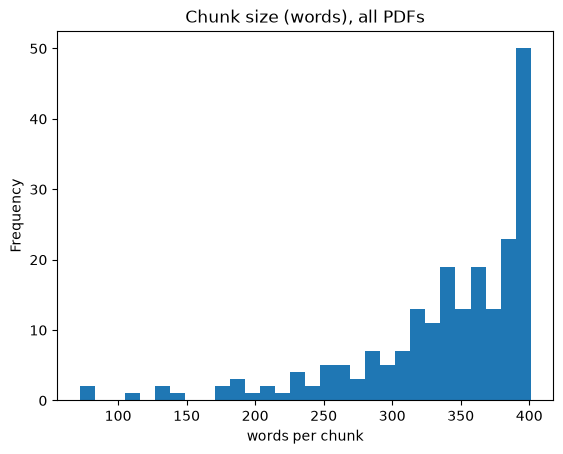

In [5]:
ax = pd.Series(
    [len(c.content.split()) for chunks in chunks_by_file.values() for c in chunks]
).plot.hist(bins=30, title="Chunk size (words), all PDFs")
ax.set_xlabel("words per chunk")

## Reading the results
- Prefer the extractor with fewer empty pages and a higher clean ratio; if both show many empty pages, that file needs OCR.
- Many tiny chunks usually mean headers/footers or table fragments leaking in - clean those before embedding.
- The loader in `backend/src/rag/loaders.py` currently uses `pypdf`; switch only if PyMuPDF is clearly better here.